In [1]:
import pandas as pd
import numpy as np; np.random.seed(0)
import matplotlib.pylab as plt
import seaborn as sns
import requests
import json
import locale
try:
    locale.setlocale(locale.LC_TIME, "es_ES.UTF-8")
except:
    try:
        locale.setlocale(locale.LC_TIME, "es_ES")
    except:
        pass

import matplotlib.font_manager as fm
import argparse
import matplotlib

In [2]:
# ## Acceder a los datos de precipitación procesadas en Delft-FEWS para Cuencas Hidrográficas Nivel 2
# 
# **Importante** Se recomienda estar conectado a la VPN de Presidencia para acceder a travez de Servicio web 
# Define arguments
"""
parser = argparse.ArgumentParser(
                    prog='daily_rainfall_n2.py',
                    description='Plot SDI for a specific station and time scales',
                    epilog='Jose Valles, DINAGUA, 26082024')
parser.add_argument('user_start_date', help='fecha_inicio en formato YYYY-MM-DD')      
parser.add_argument('user_end_date', help='fecha_fin en formato YYYY-MM-DD')     

args = parser.parse_args()
"""
args = argparse.Namespace(
    user_start_date='2026-09-22',
    user_end_date='2026-10-21',

)

user_start_date = args.user_start_date
adjust_start_date = pd.to_datetime(user_start_date) + pd.Timedelta(days=1)
user_end_date = args.user_end_date
adjust_end_date = pd.to_datetime(user_end_date) + pd.Timedelta(days=1)

In [3]:
url_base = 'http://prodterh-fssaws:8080/FewsWebServices/rest/fewspiservice/v1/timeseries?'
headers = {'Accept':'application/json'}
# Parametros de busqueda para MAP en cuenca nivel 2
documentVersion = '1.24'
documentFormat = 'PI_JSON'
filterid = 'CuencaNivel2'
parameterIds = 'P.cuenca'
moduleInstanceIds = 'PreprocessP'

# Fecha de inicio de busqueda y finalización. Formato requerido por FEWS: yyyy-MM-dd'T'HH:mm:ss'Z'
startTime = adjust_start_date.strftime('%Y-%m-%dT10:00:00Z')
endTime = adjust_end_date.strftime('%Y-%m-%dT10:00:00Z')

print(f"Parámetros de búsqueda:")
print(f"  Fecha inicio: {startTime}")
print(f"  Fecha fin: {endTime}")

# URL de busqueda de datos de MAP 
url = f"{url_base}filterId={filterid}&parameterIds={parameterIds}&moduleInstanceIds={moduleInstanceIds}&startTime={startTime}&endTime={endTime}&documentFormat={documentFormat}"

Parámetros de búsqueda:
  Fecha inicio: 2026-09-23T10:00:00Z
  Fecha fin: 2026-10-22T10:00:00Z


In [4]:
# Abrir consulta con parametros de busqueda
try:
    print(f"Conectando a: {url}")
    r = requests.get(url, headers=headers, timeout=30)
    
    # Validar status code
    if r.status_code != 200:
        print(f"Error: Status Code {r.status_code}")
        print(f"Respuesta: {r.text[:500]}")
        raise ValueError(f"Servicio web retornó: {r.status_code}")
    
    # Validar que la respuesta no esté vacía
    if not r.content:
        print("Error: La respuesta del servidor está vacía")
        print("Posibles causas: VPN desconectada, servicio web no disponible o rango de fechas sin datos")
        raise ValueError("Respuesta vacía del servidor")
    
    # Intentar parsear JSON
    data = json.loads(r.content.decode('utf-8'))
    print(f"✓ Datos obtenidos exitosamente: {len(data.get('timeSeries', []))} series temporales")
    
except requests.exceptions.Timeout:
    print("Error: Timeout - El servidor tardó demasiado en responder")
    raise
except requests.exceptions.ConnectionError:
    print("Error: No se puede conectar al servidor. Verificar VPN y conectividad")
    raise
except json.JSONDecodeError as e:
    print(f"Error: Respuesta inválida - No es JSON válido")
    print(f"Contenido: {r.text[:200]}")
    raise
except Exception as e:
    print(f"Error inesperado: {str(e)}")
    raise
finally:
    if 'r' in locals():
        r.close()

Conectando a: http://prodterh-fssaws:8080/FewsWebServices/rest/fewspiservice/v1/timeseries?filterId=CuencaNivel2&parameterIds=P.cuenca&moduleInstanceIds=PreprocessP&startTime=2026-09-23T10:00:00Z&endTime=2026-10-22T10:00:00Z&documentFormat=PI_JSON
✓ Datos obtenidos exitosamente: 78 series temporales


In [7]:
allbasins_n2 = pd.read_csv('../waterbalance/cuencas_nombres.csv')

# Identificar dinámicamente la columna que contiene los códigos de cuenca
posibles_cols_codigo = ['codigo', 'id', 'Id', 'CODIGO', 'code', 'basin_id']
col_codigo = next((col for col in posibles_cols_codigo if col in allbasins_n2.columns), allbasins_n2.columns[0])
allbasins_n2[col_codigo] = allbasins_n2[col_codigo].astype(str)

In [8]:
df = pd.DataFrame()
for x in range(len(data['timeSeries'])):
    extraer_estacion = str(data['timeSeries'][x]['header']['locationId'])
    datos_estacion = pd.DataFrame(data['timeSeries'][x]['events'])
    df[extraer_estacion] = datos_estacion['value'].values

# Une los datos de fecha y hora
datos_estacion = datos_estacion.drop(columns=['value', 'flag'])
datos_estacion = pd.to_datetime(datos_estacion['date'] + ' ' + datos_estacion['time'])
datos_estacion = datos_estacion.to_frame()

# Une los datos con las fechas de serie de tiempo
df = pd.concat([datos_estacion, df], axis=1, join='inner')
df = df.rename(columns={0: 'FECHA'})

# Convierte la hora de UTC a UTC-0300 (hora Montevideo)
df['FECHA'] = df['FECHA'] - pd.Timedelta(hours=3)
df['FECHA'] = df['FECHA'] - pd.Timedelta(days=1)
df = df.filter(regex='^(?!6060)')

In [9]:
# Selección dinámica y flexible de cuencas (sin hardcodear lista estática)
codigos_csv = allbasins_n2[col_codigo].values
basin_cols = [c for c in codigos_csv if c in df.columns]

# En caso de haber columnas de estaciones en df que no están en el CSV, agregarlas al final
extra_cols = [str(c) for c in df.columns if c != 'FECHA' and str(c) not in basin_cols]
basin_cols = basin_cols + extra_cols

# Filtrar y forzar tipos numéricos
df = df[['FECHA'] + basin_cols]
df[basin_cols] = df[basin_cols].apply(pd.to_numeric, errors='coerce')

In [10]:
piv = pd.pivot_table(df, values=basin_cols, columns=["FECHA"], aggfunc='mean')
piv[piv < 0] = np.nan

In [11]:
piv2 = piv.transpose()

In [12]:
def plot_heatmap_transposed(piv2_df, df_original, allbasins_df, output_file=None):
    """
    Genera un heatmap con datos transpostos (fechas en rows, cuencas en columns).
    """
    font_size = 12
    fig, ax = plt.subplots(figsize=(28, 14))
    
    values = piv2_df.to_numpy(dtype=float)
    cmap = "Blues"
    
    ax = sns.heatmap(piv2_df, square=True, cmap=cmap, annot=False, vmin=0, vmax=100,
                     linewidths=1.0, linecolor='black', annot_kws={'fontsize': 8},
                     cbar_kws={"shrink": 0.5, "label": 'Precipitación [mm]'},
                     mask=values < 1, ax=ax)
    
    ax.set_title('Lluvia registrada en cuencas hidrográficas nivel 2', pad=20, loc='center', size=18)
    
    # Eje Y: Fechas únicas del índice pivotado
    fechas_y = pd.to_datetime(piv2_df.index).strftime('%d-%b')
    ax.set_ylabel('Día-Mes-Año', rotation=90, labelpad=10, size=font_size)
    ax.set_yticks(np.arange(len(fechas_y)) + 0.5)
    ax.set_yticklabels(fechas_y, fontsize=font_size)
    
    # Eje X: Nombres mapeados según los códigos de columnas
    dict_nombres = dict(zip(allbasins_df[col_codigo].astype(str), allbasins_df['nombre']))
    nombres_x = [dict_nombres.get(str(cod), str(cod)) for cod in piv2_df.columns]
    
    ax.set_xlabel('Codigo de cuenca hidrográfica nivel 2', rotation=0, labelpad=10, fontsize=font_size)
    ax.set_xticks(np.arange(len(nombres_x)) + 0.5)
    ax.set_xticklabels(nombres_x, rotation=90, fontsize=font_size)
    
    colorbar = ax.collections[0].colorbar
    colorbar.ax.tick_params(labelsize=font_size)
    ax.figure.axes[-1].yaxis.label.set_size(font_size)
    
    plt.rcParams.update({'font.family': 'Arial'})
    sns.set(font_scale=1.4)
    
    if output_file:
        plt.savefig(output_file, dpi=300, bbox_inches='tight')

    return fig, ax


def plot_heatmap_grouped(piv_df, df_original, allbasins_df, 
                          output_file=None, 
                          x_lim_left=-1.5, 
                          x_line_div=-0.9, 
                          margin_left=0.45):
    """
    Genera un heatmap con agrupación por cuencas principales.
    
    Parameters:
    -----------
    piv_df : pd.DataFrame
        Dataframe pivotado (cuencas como rows, fechas como columns).
    df_original : pd.DataFrame
        Dataframe original con columna FECHA.
    allbasins_df : pd.DataFrame
        Dataframe con información de cuencas (códigos y nombres).
    output_file : str, optional
        Ruta para guardar la imagen generada.
    x_lim_left : float, optional
        Posición horizontal del borde exterior izquierdo (por defecto -1.5).
    x_line_div : float, optional
        Posición de la línea divisoria vertical entre los nombres de grupo y 
        los nombres de subcuencas (por defecto -0.9).
    margin_left : float, optional
        Margen izquierdo de la figura en subplots_adjust (por defecto 0.45).
    """
    font_size = 12
    ancho_linea = 2
    
    # Definir mapeo de grupos
    group_map = {
        '1': 'Río Uruguay',
        '2': 'Río de la Plata',
        '3': 'Océano Atlántico',
        '4': 'Laguna Merín',
        '5': 'Río Negro',
        '6': 'Río Santa Lucia'
    }
    
    basin_groups = [group_map.get(str(code)[0], "Otro") for code in piv_df.index]
    change_indices = np.where(np.array(basin_groups)[:-1] != np.array(basin_groups)[1:])[0]
    
    fig, ax = plt.subplots(figsize=(28, 14))
    values = piv_df.to_numpy(dtype=float)
    
    sns.set(font_scale=1)
    plt.subplots_adjust(left=margin_left)
    
    ax = sns.heatmap(piv_df, square=True, cmap="Blues", vmin=0, vmax=100,
                     annot=False, linewidths=1.0, linecolor='black',
                     annot_kws={'fontsize': 8},
                     cbar_kws={"shrink": 0.5, "label": 'Precipitación [mm]'},
                     mask=values < 3, ax=ax)
    
    # Agregar etiquetas de grupo y bordes horizontales
    last_idx = 0
    
    for idx in list(change_indices) + [len(basin_groups) - 1]:
        mid_point = (last_idx + idx + 1) / 2
        group_name = basin_groups[last_idx]
        
        # Centrar el texto del grupo entre el borde exterior y la línea divisoria
        ax.annotate(group_name, xy=((x_lim_left + x_line_div) / 2, mid_point),
                    xycoords=('axes fraction', 'data'),
                    ha='center', va='center', fontweight='bold', fontsize=16)
        
        ax.axhline(y=idx + 1, xmin=x_lim_left, xmax=1.0,
                   color='black', linewidth=ancho_linea, clip_on=False)
        
        if last_idx == 0:
            ax.axhline(y=0, xmin=x_lim_left, xmax=1.0,
                       color='black', linewidth=ancho_linea, clip_on=False)
        
        last_idx = idx + 1
    
    # Borde vertical exterior izquierdo
    ax.vlines(x=x_lim_left, ymin=0, ymax=len(piv_df), transform=ax.get_yaxis_transform(),
              color='black', linewidth=ancho_linea, clip_on=False)
    
    # Línea vertical divisoria entre grupos y subcuencas
    ax.vlines(x=x_line_div, ymin=0, ymax=len(piv_df), transform=ax.get_yaxis_transform(),
              color='black', linewidth=ancho_linea, clip_on=False)
    
    # Eje X: fechas agregadas de las columnas de piv_df
    fechas_x = pd.to_datetime(piv_df.columns).strftime('%d-%b').str.upper()
    ax.set_xlabel('Día-Mes', rotation=0, labelpad=10, size=font_size)
    ax.set_xticks(np.arange(len(fechas_x)) + 0.5)
    ax.set_xticklabels(fechas_x, rotation=90, fontsize=font_size)
    
    # Eje Y: nombres dinámicos mapeados desde allbasins_df
    dict_nombres = dict(zip(allbasins_df[col_codigo].astype(str), allbasins_df['nombre']))
    nombres_y = [dict_nombres.get(str(cod), str(cod)) for cod in piv_df.index]
    
    ax.tick_params(axis='y', labelsize=font_size)
    ax.set_yticks(np.arange(len(nombres_y)) + 0.5)
    ax.set_yticklabels(nombres_y, rotation=0)
    
    colorbar = ax.collections[0].colorbar
    colorbar.ax.tick_params(labelsize=font_size)
    colorbar.ax.yaxis.set_tick_params(rotation=90)
    colorbar.ax.yaxis.set_label_position('left')
    ax.figure.axes[-1].yaxis.label.set_size(font_size)
    
    plt.rcParams.update({'font.family': 'Arial'})
    sns.set(font_scale=1.4)
    
    if output_file:
        plt.savefig(output_file, dpi=300, bbox_inches='tight')
    
    return fig, ax


def plot_heatmap_simple(piv_df, df_original, allbasins_df, output_file=None):
    """
    Genera un heatmap simple sin agrupación.
    """
    font_size = 14
    fig, ax = plt.subplots(figsize=(28, 14))
    values = piv_df.to_numpy(dtype=float)
    
    sns.set(font_scale=1)
    
    ax = sns.heatmap(piv_df, square=True, cmap="Blues", vmin=0, vmax=100,
                     annot=False, linewidths=1.0, linecolor='black',
                     annot_kws={'fontsize': 8},
                     cbar_kws={"shrink": 0.5, "label": 'Precipitación [mm]'},
                     mask=values < 3, ax=ax)
    
    ax.set_title('Lluvia registrada en cuencas hidrográficas nivel 2', pad=20, loc='center', size=18)
    
    fechas_x = pd.to_datetime(piv_df.columns).strftime('%d-%b')
    ax.set_xlabel('Día-Mes-Año', rotation=0, labelpad=10, size=font_size)
    ax.set_xticks(np.arange(len(fechas_x)) + 0.5)
    ax.set_xticklabels(fechas_x, rotation=90, fontsize=font_size)
    
    dict_nombres = dict(zip(allbasins_df[col_codigo].astype(str), allbasins_df['nombre']))
    nombres_y = [dict_nombres.get(str(cod), str(cod)) for cod in piv_df.index]
    
    ax.set_ylabel('Codigo de cuenca hidrográfica nivel 2', rotation=90, labelpad=10, fontsize=font_size)
    ax.tick_params(axis='y', labelsize=font_size)
    ax.set_yticks(np.arange(len(nombres_y)) + 0.5)
    ax.set_yticklabels(nombres_y, rotation=0)
    
    colorbar = ax.collections[0].colorbar
    colorbar.ax.tick_params(labelsize=font_size)
    colorbar.ax.yaxis.set_tick_params(rotation=90)
    colorbar.ax.yaxis.set_label_position('left')
    ax.figure.axes[-1].yaxis.label.set_size(font_size)
    
    plt.rcParams.update({'font.family': 'Arial'})
    sns.set(font_scale=1.4)
    
    if output_file:
        plt.savefig(output_file, dpi=300, bbox_inches='tight')
    
    return fig, ax

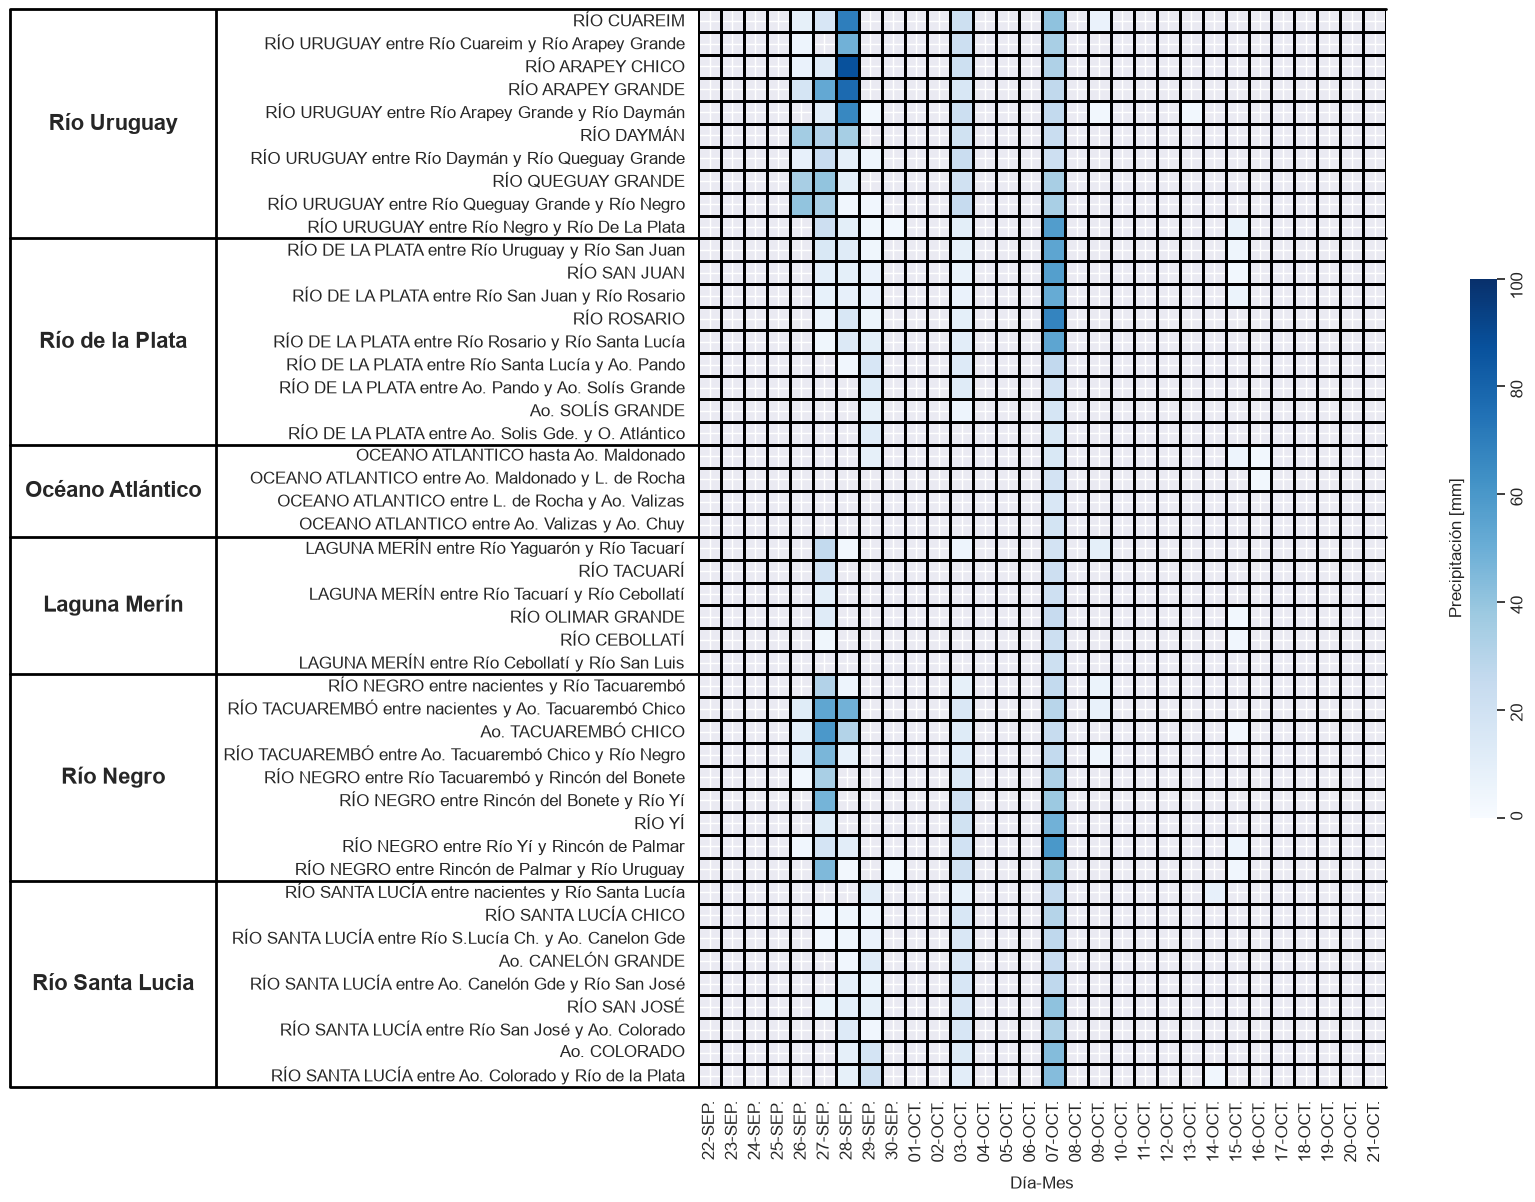

Grafico generado exitosamente.


In [15]:
fig2, ax2 = plot_heatmap_grouped(
    piv, df, allbasins_n2,
    output_file="",
    x_lim_left=-1.0,
    x_line_div=-0.70,
    margin_left=0.30
)
plt.show()
print("Grafico generado exitosamente.")